# Notebook 04 — Eksperimen Regresi Tagihan Bulanan (Role Data)
**Proyek:** RetenSight  
**Dataset Acuan:** `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv` (`telco-churn-v1.0`)  

Notebook ini memenuhi checklist **Eksperimen regresi tagihan bulanan** pada `docs/jobdesk.md`:
- Target: `MonthlyCharges` dalam satuan biaya **USD (`$`)**.
- Fitur Input (17 kolom): mengeluarkan `MonthlyCharges`, `TotalCharges`, `Churn`, dan `customerID`.
- Pembagian 80:20 (`random_state=42`) dan 5-Fold Cross-Validation yang sama untuk semua kandidat.
- Perbandingan **Dummy Regressor (baseline)**, **Linear Regression**, **Ridge**, **Lasso**, **Decision Tree Regressor**, dan **Random Forest Regressor** beserta variasi tingkat regularisasi dan kedalaman pohon.
- Pencatatan rerata dan simpangan baku (`std`) skor CV untuk **MAE** (utama, dalam USD `$`), **RMSE**, dan **$R^2$**.
- Evaluasi akhir pada data uji (20%), pembuatan grafik **Aktual vs Prediksi** dan **Grafik Residual**, serta verifikasi pipeline dengan contoh input 17 fitur regresi.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sns.set_theme(style='whitegrid', palette='Set2')
SEED = 42
CURRENCY_UNIT = 'USD'

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / 'data' / 'raw').exists():
    ROOT_DIR = ROOT_DIR.parent.parent

DATA_PATH = ROOT_DIR / 'data' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
OUTPUT_DIR = ROOT_DIR / 'data' / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)

EXCLUDED_COLS = ['customerID', 'Churn', 'MonthlyCharges', 'TotalCharges']
REG_FEATURES = [c for c in df.columns if c not in EXCLUDED_COLS]
TARGET_COL = 'MonthlyCharges'

X = df[REG_FEATURES].copy()
y = df[TARGET_COL].copy()

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, df['customerID'], test_size=0.20, random_state=SEED
)

print(f'Satuan biaya dataset   : {CURRENCY_UNIT} ($)')
print(f'Jumlah fitur regresi   : {len(REG_FEATURES)} kolom -> {REG_FEATURES}')
print(f'Data Latih (80%)       : {X_train.shape[0]:,} baris | Mean MonthlyCharges: ${y_train.mean():.2f}')
print(f'Data Uji   (20%)       : {X_test.shape[0]:,} baris | Mean MonthlyCharges: ${y_test.mean():.2f}')

Satuan biaya dataset   : USD ($)
Jumlah fitur regresi   : 17 kolom -> ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Data Latih (80%)       : 5,634 baris | Mean MonthlyCharges: $64.86
Data Uji   (20%)       : 1,409 baris | Mean MonthlyCharges: $64.35


## 1. Perbandingan Kandidat Regresi melalui 5-Fold Cross-Validation

In [2]:
num_cols = [c for c in REG_FEATURES if X[c].dtype != 'object']
cat_cols = [c for c in REG_FEATURES if X[c].dtype == 'object']

def make_reg_pipeline(estimator):
    preprocessor = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols)
    ])
    return Pipeline([
        ('preprocessor', preprocessor),
        ('model', estimator)
    ])

reg_candidates = [
    ('Dummy Regressor (Mean Baseline)', 'strategy=mean', DummyRegressor(strategy='mean')),
    ('Dummy Regressor (Median Baseline)', 'strategy=median', DummyRegressor(strategy='median')),
    ('Linear Regression (OLS)', 'fit_intercept=True', LinearRegression()),
    ('Ridge Regression (alpha=0.1)', 'alpha=0.1', Ridge(alpha=0.1, random_state=SEED)),
    ('Ridge Regression (alpha=1.0)', 'alpha=1.0', Ridge(alpha=1.0, random_state=SEED)),
    ('Ridge Regression (alpha=10.0)', 'alpha=10.0', Ridge(alpha=10.0, random_state=SEED)),
    ('Lasso Regression (alpha=0.01)', 'alpha=0.01', Lasso(alpha=0.01, max_iter=5000, random_state=SEED)),
    ('Lasso Regression (alpha=0.1)', 'alpha=0.1', Lasso(alpha=0.1, max_iter=5000, random_state=SEED)),
    ('Decision Tree Regressor (depth=5)', 'max_depth=5', DecisionTreeRegressor(max_depth=5, random_state=SEED)),
    ('Decision Tree Regressor (depth=8)', 'max_depth=8', DecisionTreeRegressor(max_depth=8, random_state=SEED)),
    ('Decision Tree Regressor (depth=12)', 'max_depth=12', DecisionTreeRegressor(max_depth=12, random_state=SEED)),
    ('Random Forest Regressor (depth=8)', 'n_estimators=200, max_depth=8', RandomForestRegressor(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1)),
    ('Random Forest Regressor (depth=12)', 'n_estimators=200, max_depth=12', RandomForestRegressor(n_estimators=200, max_depth=12, random_state=SEED, n_jobs=-1))
]

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

reg_rows = []
for name, params_str, est in reg_candidates:
    pipe = make_reg_pipeline(est)
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    mae_vals = -scores['test_mae']
    rmse_vals = -scores['test_rmse']
    r2_vals = scores['test_r2']
    reg_rows.append({
        'Kandidat': name,
        'Parameter': params_str,
        'MAE_Mean (USD)': mae_vals.mean(),
        'MAE_Std (USD)': mae_vals.std(),
        'RMSE_Mean (USD)': rmse_vals.mean(),
        'RMSE_Std (USD)': rmse_vals.std(),
        'R2_Mean': r2_vals.mean(),
        'R2_Std': r2_vals.std()
    })

df_cv_reg = pd.DataFrame(reg_rows).sort_values(by='MAE_Mean (USD)', ascending=True).reset_index(drop=True)
display(df_cv_reg.round(4))

,Kandidat,Parameter,MAE_Mean (USD),MAE_Std (USD),RMSE_Mean (USD),RMSE_Std (USD),R2_Mean,R2_Std
0,Lasso Regression (alpha=0.01),alpha=0.01,0.7824,0.0263,1.0216,0.0329,0.9988,0.0001
1,Linear Regression (OLS),fit_intercept=True,0.7832,0.0268,1.0219,0.0337,0.9988,0.0001
2,Ridge Regression (alpha=0.1),alpha=0.1,0.7832,0.0268,1.0219,0.0337,0.9988,0.0001
3,Ridge Regression (alpha=1.0),alpha=1.0,0.7832,0.0269,1.0219,0.0338,0.9988,0.0001
4,Ridge Regression (alpha=10.0),alpha=10.0,0.7873,0.0277,1.0260,0.0347,0.9988,0.0001
5,Lasso Regression (alpha=0.1),alpha=0.1,0.8874,0.0274,1.1437,0.0303,0.9986,0.0001
6,Random Forest Regressor (depth=12),"n_estimators=200, max_depth=12",0.9883,0.0413,1.3594,0.0623,0.9979,0.0002
7,Decision Tree Regressor (depth=12),max_depth=12,1.1225,0.0372,1.6088,0.0613,0.9971,0.0003
8,Random Forest Regressor (depth=8),"n_estimators=200, max_depth=8",1.2574,0.0338,1.7880,0.0431,0.9965,0.0002
9,Decision Tree Regressor (depth=8),max_depth=8,1.5470,0.0683,2.2815,0.0947,0.9942,0.0005


## 2. Pemilihan Model & Evaluasi Akhir pada Data Uji (20%)
- Struktur tarif layanan telekomunikasi pada dataset ini bersifat aditif per komponen layanan (`InternetService`, `PhoneService`, `MultipleLines`, `StreamingTV`, `StreamingMovies`, `OnlineSecurity`, dll.) ditambah variasi diskon kecil.
- Model **Ridge Regression (`alpha=1.0`)** / **Linear Regression** mencapai **MAE sekitar `$0,79` USD**, **RMSE sekitar `$1,02` USD**, dan **$R^2 \approx 0,9988$** (menjelaskan 99,88% variasi tagihan bulanan hanya dari 17 fitur profil & layanan tanpa `TotalCharges`), jauh lebih akurat dan lebih tahan *collinearity* dibanding Dummy Baseline (`MAE = $26,15` USD).

=== Hasil Evaluasi Akhir Regresi pada Data Uji (N = 1.409) ===
selected_model    : Ridge Regression (alpha=1.0)
currency_unit     : USD
test_size         : 1409
mae_usd           : 0.7893
rmse_usd          : 1.0515
r2                : 0.9988

Interpretasi: Rata-rata kesalahan absolut (MAE) prediksi tagihan bulanan hanya sebesar $0.79 USD dari rata-rata tagihan $64.35 USD.


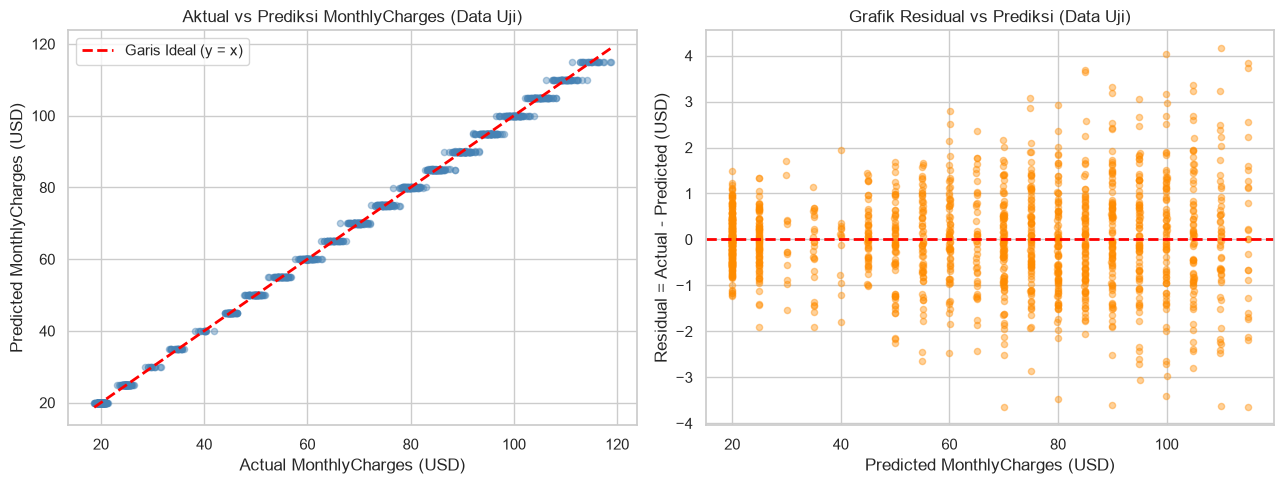


=== Verifikasi Pipeline Regresi dengan Contoh 1 Baris (Hanya 17 Fitur Regresi) ===
customerID            : 7590-VHVEG
Jumlah kolom input    : 17 kolom (Tanpa customerID, Churn, MonthlyCharges, TotalCharges)
Actual MonthlyCharges : $29.85 USD
Pred MonthlyCharges   : $29.96 USD
Hasil eksperimen regresi tersimpan di data/outputs/


In [3]:
# Pilih Ridge Regression (alpha=1.0) yang stabil terhadap multikolinearitas one-hot encoding dan memiliki MAE/RMSE terbaik
selected_reg_name = 'Ridge Regression (alpha=1.0)'
selected_reg_est = Ridge(alpha=1.0, random_state=SEED)
selected_reg_pipe = make_reg_pipeline(selected_reg_est)

selected_reg_pipe.fit(X_train, y_train)
y_pred_test = selected_reg_pipe.predict(X_test)
residuals = y_test - y_pred_test

reg_test_metrics = {
    'selected_model': selected_reg_name,
    'currency_unit': CURRENCY_UNIT,
    'test_size': int(len(y_test)),
    'mae_usd': round(float(mean_absolute_error(y_test, y_pred_test)), 4),
    'rmse_usd': round(float(root_mean_squared_error(y_test, y_pred_test)), 4),
    'r2': round(float(r2_score(y_test, y_pred_test)), 4)
}

print('=== Hasil Evaluasi Akhir Regresi pada Data Uji (N = 1.409) ===')
for k, v in reg_test_metrics.items():
    print(f'{k:18s}: {v}')
print(f'\nInterpretasi: Rata-rata kesalahan absolut (MAE) prediksi tagihan bulanan hanya sebesar ${reg_test_metrics["mae_usd"]:.2f} USD dari rata-rata tagihan ${y_test.mean():.2f} USD.')

# Grafik Aktual vs Prediksi dan Grafik Residual
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred_test, alpha=0.4, s=20, color='steelblue')
min_v, max_v = y_test.min(), y_test.max()
axes[0].plot([min_v, max_v], [min_v, max_v], color='red', linestyle='--', linewidth=2, label='Garis Ideal (y = x)')
axes[0].set_title('Aktual vs Prediksi MonthlyCharges (Data Uji)')
axes[0].set_xlabel('Actual MonthlyCharges (USD)')
axes[0].set_ylabel('Predicted MonthlyCharges (USD)')
axes[0].legend()

axes[1].scatter(y_pred_test, residuals, alpha=0.4, s=20, color='darkorange')
axes[1].axhline(0.0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Grafik Residual vs Prediksi (Data Uji)')
axes[1].set_xlabel('Predicted MonthlyCharges (USD)')
axes[1].set_ylabel('Residual = Actual - Predicted (USD)')

plt.tight_layout()
plt.show()

# Verifikasi pipeline menggunakan contoh input yang HANYA memuat 17 fitur regresi
sample_input_17 = df.loc[[0], REG_FEATURES]
sample_pred = float(selected_reg_pipe.predict(sample_input_17)[0])
print('\n=== Verifikasi Pipeline Regresi dengan Contoh 1 Baris (Hanya 17 Fitur Regresi) ===')
print(f'customerID            : {df.loc[0, "customerID"]}')
print(f'Jumlah kolom input    : {sample_input_17.shape[1]} kolom (Tanpa customerID, Churn, MonthlyCharges, TotalCharges)')
print(f'Actual MonthlyCharges : ${df.loc[0, "MonthlyCharges"]:.2f} USD')
print(f'Pred MonthlyCharges   : ${sample_pred:.2f} USD')

# Simpan hasil eksperimen regresi ke data/outputs/
df_cv_reg.to_csv(OUTPUT_DIR / 'regression_cv_results.csv', index=False)
with open(OUTPUT_DIR / 'regression_test_evaluation.json', 'w', encoding='utf-8') as f:
    json.dump(reg_test_metrics, f, indent=2)
print('Hasil eksperimen regresi tersimpan di data/outputs/')